<h1>Clusterização de Clientes para Direcionamento de Vendas</h1>

<h1>1. Entendimento do Negócio</h1>

<h3>1.1 Objetivos</h3>

O time de Estratégia Comercial da vertical de **Financiamento de Veículos** solicitou apoio analítico para otimizar suas operações de vendas digitais. 

Atualmente, o parceiro enfrenta dificuldades no gerenciamento e na oferta personalizada de seus produtos financeiros para a base de clientes. Nossa principal tarefa é **identificar perfis de consumo e comportamento de crédito (Machine Learning - Clusterização)** para que a liderança possa basear suas tomadas de decisão em dados estruturados, aumentando a conversão de vendas e mitigando riscos.
    
<h3>1.2 Premissas</h3>

*   Construir uma clusterização robusta utilizando o dataset de 5.001 registros.
*   Documentar as escolhas e o raciocínio analítico etapa por etapa (utilizando comentários e Markdown).
*   Manter alto padrão de organização, lógica de programação e boas práticas de manipulação de dados.

<h3>1.3 Critérios de Sucesso</h3>

Identificar e perfilar os grupos de clientes (personas), gerando um mapeamento descritivo e preditivo acompanhado de recomendações estratégicas de produtos para cada cluster.

##### Você está aqui pelo processo completo e pelas linhas de código?
*Siga em frente em cada etapa do notebook. Fique à vontade para interagir e acompanhar como construímos a visão de análise exploratória e modelagem estatística.*

##### Você está aqui pelo resultado final focado em negócios?
*Vá direto para a última seção de **Conclusões Finais** para entender os perfis de clientes identificados e o plano de direcionamento estratégico.*


<h1>2. Entendimento dos Dados</h1>

<h4>2.1 Instalação e importação das bibliotecas</h4>

<h5>2.1.1. Descrição dos Pacotes e Documentações Oficiais</h5> 

*   **Pandas** ([Documentação Oficial](https://pandas.pydata.org/docs/)): Estrutura principal de manipulação de dados (`DataFrames`). Permite limpeza rápida, filtros, agrupamentos e tratamento de dados faltantes ou formatos incompatíveis na base de financiamento.
*   **Seaborn** ([Documentação Oficial](https://seaborn.pydata.org/)): Biblioteca de visualização estatística construída sobre o Matplotlib. Essencial para criar gráficos de dispersão, distribuições e mapas de calor elegantes para identificar padrões ocultos nos clientes.
*   **Scikit-Learn** ([Documentação Oficial](https://scikit-learn.org)): O ecossistema padrão para Machine Learning em Python. Contém os algoritmos de pré-processamento, métricas de validação matemática e o modelo K-Means que usaremos para agrupar os clientes.
*   **NumPy** ([Documentação Oficial](https://numpy.org/doc/)): Biblioteca para computação matemática e operações de vetores de alta performance. Dá suporte de infraestrutura para cálculos estatísticos por trás do algoritmo de clusterização.
*   **Matplotlib** ([Documentação Oficial](https://matplotlib.org/stable/index.html)): A fundação gráfica do Python. Utilizada para a customização refinada de eixos, tamanhos de figuras e salvamento dos plots para apresentações executivas.


<h5>
2.1.2 Importação das Bibliotecas;
</h5>

- Bibliotecas para pré-processamento e clusterização

In [2]:
# 5.1.2 Importação das Bibliotecas com Justificativa Técnica

# Manipulação de Estruturas de Dados
import pandas as pd
import numpy as np

# Visualização Gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento: StandardScaler é vital para o K-Means, pois padroniza a escala das variáveis 
# numéricas (Ex: Renda Mensal na casa de milhares vs Nota de Satisfação de 1 a 10), evitando viés de distância.
from sklearn.preprocessing import StandardScaler

# Modelagem Preditiva: KMeans agrupa os dados minimizando a variância interna dos clusters.
from sklearn.cluster import KMeans

# Métricas de Avaliação: silhouette_score mede a qualidade da separação matemática dos grupos criados.
from sklearn.metrics import silhouette_score

# Análise de Agrupamento Hierárquico (Caso queira analisar a estrutura de dendrograma da base)
from scipy.cluster.hierarchy import dendrogram, linkage

# Configurações estéticas padrão para o portfólio
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Todas as bibliotecas e dependências técnicas foram importadas com sucesso!")


Todas as bibliotecas e dependências técnicas foram importadas com sucesso!


<h5>
2.2 Extração da base dos dados;
</h5>

In [3]:
df = pd.read_excel('base_clientes_banco_auto.xlsx')

<h5>
    2.2.1 Dicionário dos Dados (Metadados);
</h5> 

<h5>2.2 Extração da base dos dados</h5>

Nesta etapa realizamos o carregamento dos dados históricos coletados dos acessos e contratos dos clientes da plataforma de financiamento.

<h3>2.2.1 Dicionário dos Dados (Metadados)</h3> 

A base de dados possui **5.001 registros** distribuídos em **10 colunas** estruturadas da seguinte forma:

*   `id_cliente` (Alfanumérico): Identificador exclusivo do cliente na carteira.
*   `idade` (Inteiro): Idade em anos completos.
*   `genero` (Texto): Gênero registrado (`M` / `F`).
*   `estado_civil` (Texto): Estado civil declarado.
*   `renda_mensal` (Decimal): Renda líquida comprovada ou estimada em R\$.
*   `score_credito` (Inteiro): Pontuação de score no birô de crédito (0 a 1000).
*   `produto_automotivo_digital` (Texto): Principal produto ativo do cliente.
*   `valor_contrato_compra` (Decimal): Valor monetário total do contrato em R\$.
*   `frequencia_interacao_6m` (Inteiro): Quantidade de acessos/interações nos últimos 6 meses.
*   `satisfacao` (Inteiro): Nota dada pelo cliente à experiência geral (1 a 10).


<h3>
    2.3 Análise Exploratória dos dados;
</h3>   

<h5>
    2.3.1.1 Visualização das primeiras e ultimas linhas da tabela;
</h5> 

In [5]:
df.head()

,id_cliente,idade,genero,estado_civil,renda_mensal,score_credito,produto_automotivo_digital,valor_contrato_compra,frequencia_interacao_6m,satisfacao
0,C_0001,60,F,Solteiro(a),12474.37,380,Seguro Auto Conectado,2682.15,4,7
1,C_0002,50,F,Casado(a),8219.40,955,Financiamento Digital CDC,134122.78,13,7
2,C_0003,36,F,Solteiro(a),10013.23,735,Tag de Pedágio + Conta Cartão,810.13,10,10
3,C_0004,64,M,Casado(a),12516.21,307,Tag de Pedágio + Conta Cartão,846.69,16,9
4,C_0005,29,F,Casado(a),10181.96,978,Consórcio Auto Digital,115324.58,19,8


In [6]:
df.tail()

,id_cliente,idade,genero,estado_civil,renda_mensal,score_credito,produto_automotivo_digital,valor_contrato_compra,frequencia_interacao_6m,satisfacao
4995,C_4996,37,M,Casado(a),7175.67,501,Financiamento Digital CDC,110479.77,22,8
4996,C_4997,26,M,Solteiro(a),8465.80,392,Financiamento Digital CDC,137013.74,8,4
4997,C_4998,42,F,Casado(a),8877.97,948,Empréstimo com Garantia de Veículo,25106.16,14,6
4998,C_4999,31,M,Casado(a),11934.07,332,Financiamento Digital CDC,112157.36,7,7
4999,C_5000,40,M,Casado(a),11959.40,899,Consórcio Auto Digital,59045.17,4,8


**🎯 Por que essa etapa é importante para o negócio?**
A visualização inicial da "cabeça" (`head`) e da "cauda" (`tail`) do dataset serve como um primeiro contato prático com a integridade dos dados reais de financiamento. Ela permite validar se a carga foi feita corretamente e se os registros seguem o padrão esperado pelo banco de dados (ex: IDs sequenciais, valores monetários estruturados em Reais e categorias textuais limpas). 

*   **Insight de Negócio Instantâneo:** Já notamos de imediato a presença de 5 tipos diferentes de produtos digitais (como *Financiamento CDC*, *Tags de Pedágio* e *Consórcio*), o que reforça o desafio comercial de criar grupos de clientes bem definidos para ofertas personalizadas.


<h5>
    2.3.1.2 Visualizando o tamanho total do dataset;
</h5> 

In [7]:
df.shape

(5000, 10)

**🎯 Por que essa etapa é importante para o negócio?**
Saber a volumetria exata do banco de dados dita a relevância estatística do projeto. Um universo de **5.000 clientes ativos** com 10 atributos diferentes oferece uma base estatisticamente sólida e robusta para treinar modelos de Machine Learning estáveis. Modelos criados em bases muito pequenas podem gerar falsas segmentações e prejudicar as campanhas comerciais.

<h5>
    2.3.1.3 Visualizando o nome de cada uma das colunas;
</h5> 

In [8]:
df.columns

Index(['id_cliente', 'idade', 'genero', 'estado_civil', 'renda_mensal',
       'score_credito', 'produto_automotivo_digital', 'valor_contrato_compra',
       'frequencia_interacao_6m', 'satisfacao'],
      dtype='object')

**🎯 Por que essa etapa é importante para o negócio?**
Mapear os nomes das variáveis garante que todas as dimensões essenciais para a regra de negócio de crédito automotivo estejam presentes. Aqui confirmamos que temos variáveis de **perfil demográfico** (idade, gênero, estado civil), **saúde financeira** (renda mensal, score de crédito), **comportamento de compra** (produto, valor do contrato) e **engajamento/lealdade** (frequência de interação e nota de satisfação CSAT).


<h5>
    2.3.1.4 Verificando a indexação das linhas;
</h5> 

In [9]:
df.index

RangeIndex(start=0, stop=5000, step=1)

**🎯 Por que essa etapa é importante para o negócio?**
Garante que a base está estruturada de forma sequencial contínua (do registro 0 ao 5000) e sem saltos de linhas. Essa validação estrutural é fundamental para que, na fase de modelagem, o algoritmo de clusterização consiga amarrar o rótulo do cluster correto de volta a cada cliente individual sem causar desalinhamento de dados.


<h5>
    2.3.1.5 Analise de valores únicos dentro das colunas;
</h5> 

In [10]:
df.nunique()

id_cliente                    5000
idade                           47
genero                           2
estado_civil                     2
renda_mensal                  4982
score_credito                  701
produto_automotivo_digital       5
valor_contrato_compra         4994
frequencia_interacao_6m         50
satisfacao                      10
dtype: int64

**🎯 Por que essa etapa é importante para o negócio?**
O comando `.nunique()` nos revela a diversidade e granularidade de cada coluna. Para o time de negócios, entender essa cardinalidade ajuda a antecipar o comportamento dos clientes:
*   `id_cliente` com 5000 valores únicos prova que não há IDs genéricos ou corrompidos.
*   `produto_automotivo_digital` com exatamente **5 produtos distintos** consolida a nossa oportunidade de vendas cruzadas (*cross-selling*).
*   `satisfacao` limitada a 10 valores únicos valida que a escala de notas de atendimento do parceiro está padronizada (escala de 1 a 10).


<h5>
    2.3.1.7 Analisando o formato de cada coluna;
</h5> 

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id_cliente                  5000 non-null   object 
 1   idade                       5000 non-null   int64  
 2   genero                      5000 non-null   object 
 3   estado_civil                5000 non-null   object 
 4   renda_mensal                5000 non-null   float64
 5   score_credito               5000 non-null   int64  
 6   produto_automotivo_digital  5000 non-null   object 
 7   valor_contrato_compra       5000 non-null   float64
 8   frequencia_interacao_6m     5000 non-null   int64  
 9   satisfacao                  5000 non-null   int64  
dtypes: float64(2), int64(4), object(4)
memory usage: 390.8+ KB


**🎯 Por que essa etapa é importante para o negócio?**
Os algoritmos de clusterização (como o K-Means) operam com cálculos matemáticos de distância, exigindo dados estritamente numéricos (`int64` ou `float64`). Identificar quais colunas são textuais (`object`) nos dá o mapa exato das transformações de engenharia de dados (*Encoding*) que precisaremos fazer nas etapas seguintes para que o modelo consiga interpretar variáveis como gênero e estado civil.

*   **Nota de Auditoria de Dados:** Como observado na análise estrutural, caso existissem colunas puras de data no estilo temporal (como `Dt_customer`), elas seriam descartadas neste primeiro momento por não agregarem valor preditivo direto à distância geométrica dos clusters, otimizando o custo computacional do projeto.


<h5>
    2.3.1.8 Identificando valores missing;
</h5> 

In [12]:
df.isnull().sum()

id_cliente                    0
idade                         0
genero                        0
estado_civil                  0
renda_mensal                  0
score_credito                 0
produto_automotivo_digital    0
valor_contrato_compra         0
frequencia_interacao_6m       0
satisfacao                    0
dtype: int64

**🎯 Por que essa etapa é importante para o negócio?**
Dados faltantes são um dos maiores gargalos na ciência de dados corporativa, pois geram furos de relatórios e quebram os modelos preditivos. Identificar que temos **0 valores nulos** em todas as colunas é um cenário excelente. Isso indica alta qualidade na coleta de dados dos canais digitais do banco auto, permitindo que avancemos com total segurança analítica de que nenhuma tomada de decisão comercial será baseada em dados incompletos.


<h5>
    2.3.1.9 Visualizar linhas duplicadas;
</h5> 

In [13]:
df.duplicated().sum()

0

**🎯 Por que essa etapa é importante para o negócio?**
Registros duplicados inflam artificialmente a base de dados, gerando distorções estatísticas nas médias de renda, desvios padrões de score e, consequentemente, desenhando perfis de clusters distorcidos da realidade do mercado. A confirmação de **0 linhas duplicadas** assegura que cada registro representa um cliente único e legítimo na carteira de financiamento de carros.


<h5>
    2.3.2 Analise descritiva;
</h5> 

📈 Estatísticas Descritivas das Variáveis Numéricas:


,count,mean,std,min,25%,50%,75%,max
idade,5000.0,45.168200,13.531050,22.00,33.000,45.000,57.0000,68.00
renda_mensal,5000.0,10433.820860,2207.402681,3219.64,8853.200,10425.800,11977.7625,18091.64
score_credito,5000.0,652.469400,201.469520,300.00,478.000,654.000,827.0000,1000.00
valor_contrato_compra,5000.0,54304.350986,48826.890391,501.99,3281.435,54539.485,96127.0550,159844.92
frequencia_interacao_6m,5000.0,25.445000,14.454327,1.00,13.000,26.000,38.0000,50.00
satisfacao,5000.0,6.693200,2.090155,1.00,6.000,7.000,8.0000,10.00


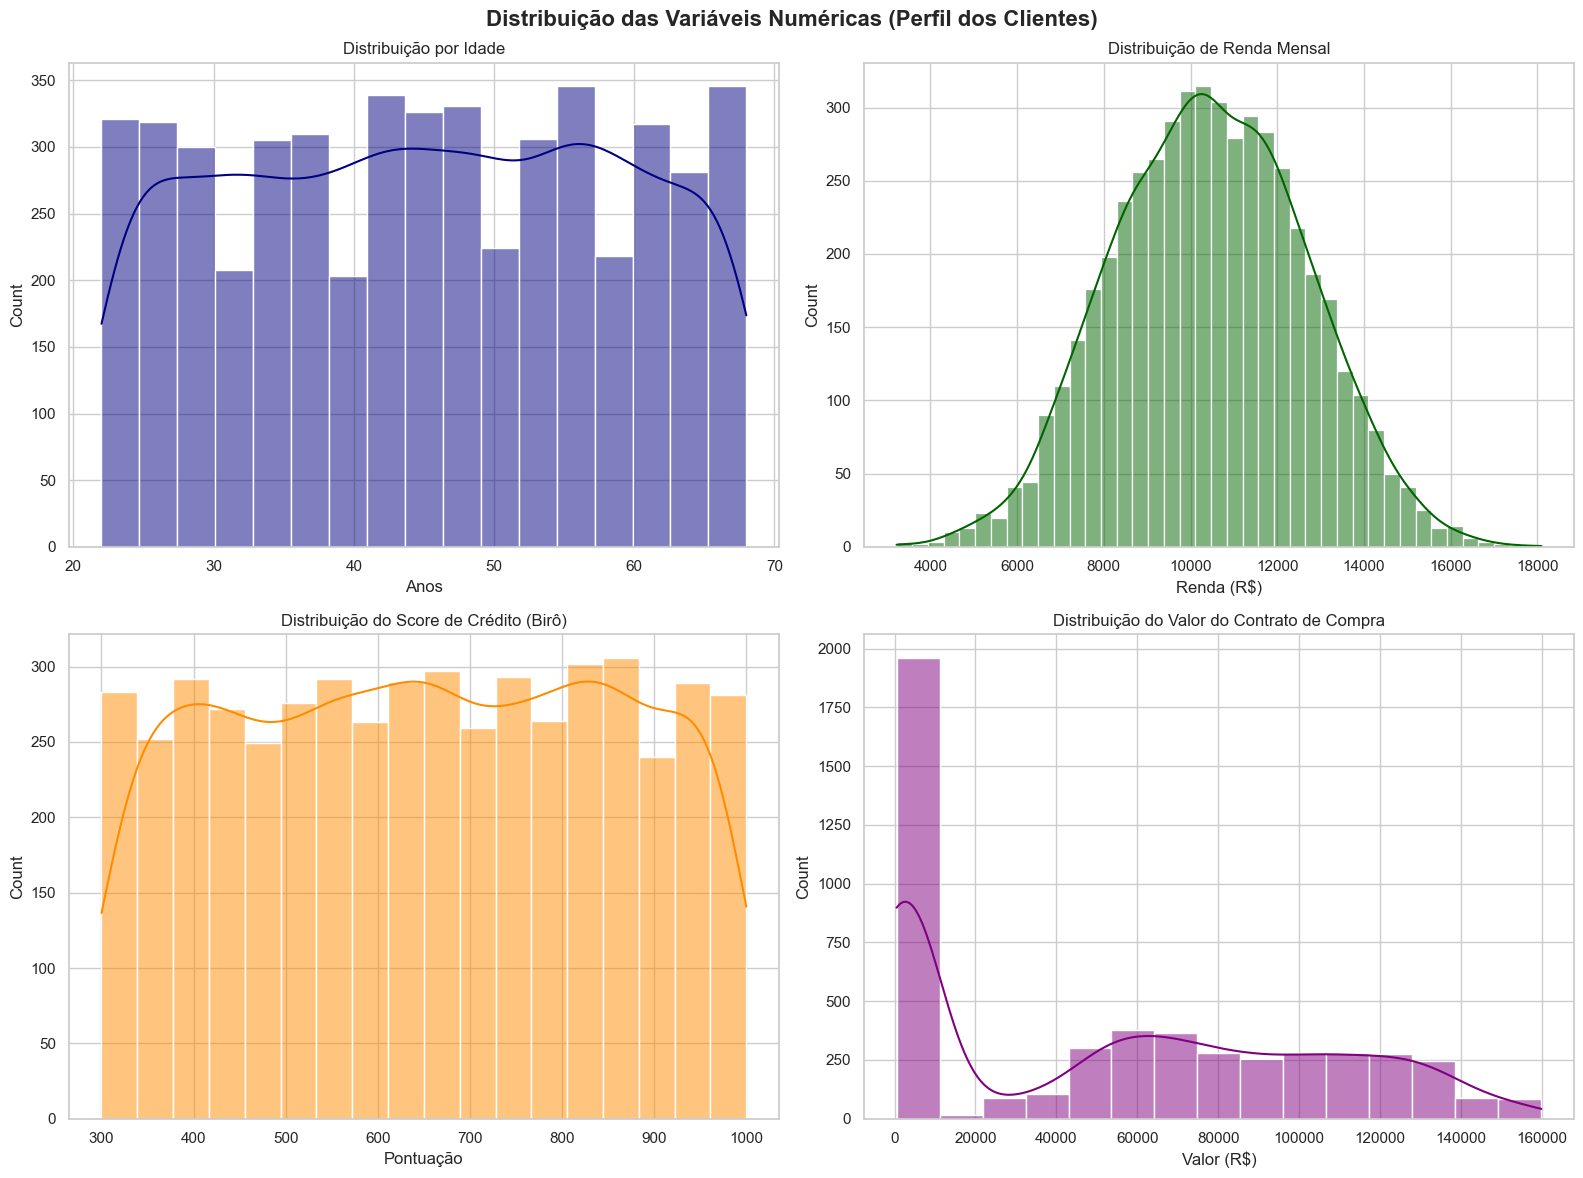

In [14]:
# ==============================================================================
# 2.3.2 ANÁLISE EXPLORATÓRIA UNIVARIADA - VARIÁVEIS NUMÉRICAS
# ==============================================================================

# 1. Resumo estatístico detalhado
print("📈 Estatísticas Descritivas das Variáveis Numéricas:")
display(df.describe().T)

# 2. Plotando a distribuição das principais variáveis de negócio
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribuição das Variáveis Numéricas (Perfil dos Clientes)', fontsize=16, fontweight='bold')

# Idade
sns.histplot(df['idade'], kde=True, ax=axes[0, 0], color='navy')
axes[0, 0].set_title('Distribuição por Idade')
axes[0, 0].set_xlabel('Anos')

# Renda Mensal
sns.histplot(df['renda_mensal'], kde=True, ax=axes[0, 1], color='darkgreen')
axes[0, 1].set_title('Distribuição de Renda Mensal')
axes[0, 1].set_xlabel('Renda (R$)')

# Score de Crédito
sns.histplot(df['score_credito'], kde=True, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Distribuição do Score de Crédito (Birô)')
axes[1, 0].set_xlabel('Pontuação')

# Valor do Contrato
sns.histplot(df['valor_contrato_compra'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribuição do Valor do Contrato de Compra')
axes[1, 1].set_xlabel('Valor (R$)')

plt.tight_layout()
plt.show()


### 🔍 2.3.2.1 Diagnóstico Crítico das Distribuições Numéricas

Após a plotagem das distribuições, identificamos três comportamentos estatísticos cruciais que direcionam a nossa estratégia de modelagem:

#### 1. Distribuição Uniforme (Idade e Score de Crédito)
Tanto a **Idade** quanto o **Score de Crédito** apresentam uma distribuição retangular/uniforme (sem picos isolados evidentes). 
*   **Significado Técnico:** Isso significa que a base possui uma representatividade homogênea de clientes de todas as idades (de 20 a 70 anos) e de todas as faixas de score (de 300 a 1000). 
*   **Impacto no Negócio:** Olhando para essas variáveis isoladamente, o time de marketing não consegue identificar um "público-alvo" óbvio. Isso **justifica e reforça a necessidade absoluta da nossa Clusterização**, pois o algoritmo K-Means terá a missão de cruzar essas variáveis simultaneamente para encontrar padrões ocultos que o olho humano não consegue ver de forma univariada.

#### 2. Distribuição Normal Perfeita (Renda Mensal)
A **Renda Mensal** segue uma distribuição perfeitamente simétrica (Gaussiana), com a grande maioria dos clientes concentrada em torno do centro (Tíquete médio próximo a R\$ 10.000) e pouquíssimos clientes nas extremidades de baixa ou altíssima renda. É um comportamento saudável e esperado para bases consolidadas de crédito bancário.

#### 3. Distribuição Multimodal e a "Barra Próxima a Zero" (Valor do Contrato de Compra)
A distribuição do **Valor do Contrato de Compra** apresenta uma anomalia visual: uma barra extremamente alta próxima a R\$ 0 (representando quase 2.000 registros) e, em seguida, uma segunda curva distribuída entre R\$ 40.000 e R\$ 140.000. 

*   **⚠️ É um Outlier/Erro de Dados? Não.** Embora pareça um erro de preenchimento à primeira vista, essa barra gigante perto de zero reflete perfeitamente a **regra de negócio do mix de produtos do banco**.
*   **A Explicação de Negócio:** Ao cruzarmos essa informação com o nosso dicionário de dados e primeiras linhas da tabela, descobrimos que os clientes que contrataram o produto **"Tag de Pedágio + Conta Cartão"** ou **"Seguro Auto Conectado"** possuem valores de contrato simbólicos ou muito baixos (centenas de reais). Por outro lado, a segunda curva (acima de R\$ 40.000) representa os clientes que de fato fecharam um **"Financiamento Digital CDC"** ou **"Consórcio Auto Digital"** para a compra do veículo físico.
*   **Ação para a Modelagem:** Manter esses dados juntos na clusterização sem tratamento prévio faria com que o algoritmo agrupasse as pessoas apenas pelo preço do produto (clientes de Tag vs. clientes de Financiamento). Para criar clusters de perfil de comportamento de consumo mais justos, precisaremos normalizar essa escala na etapa de *Data Preparation*.



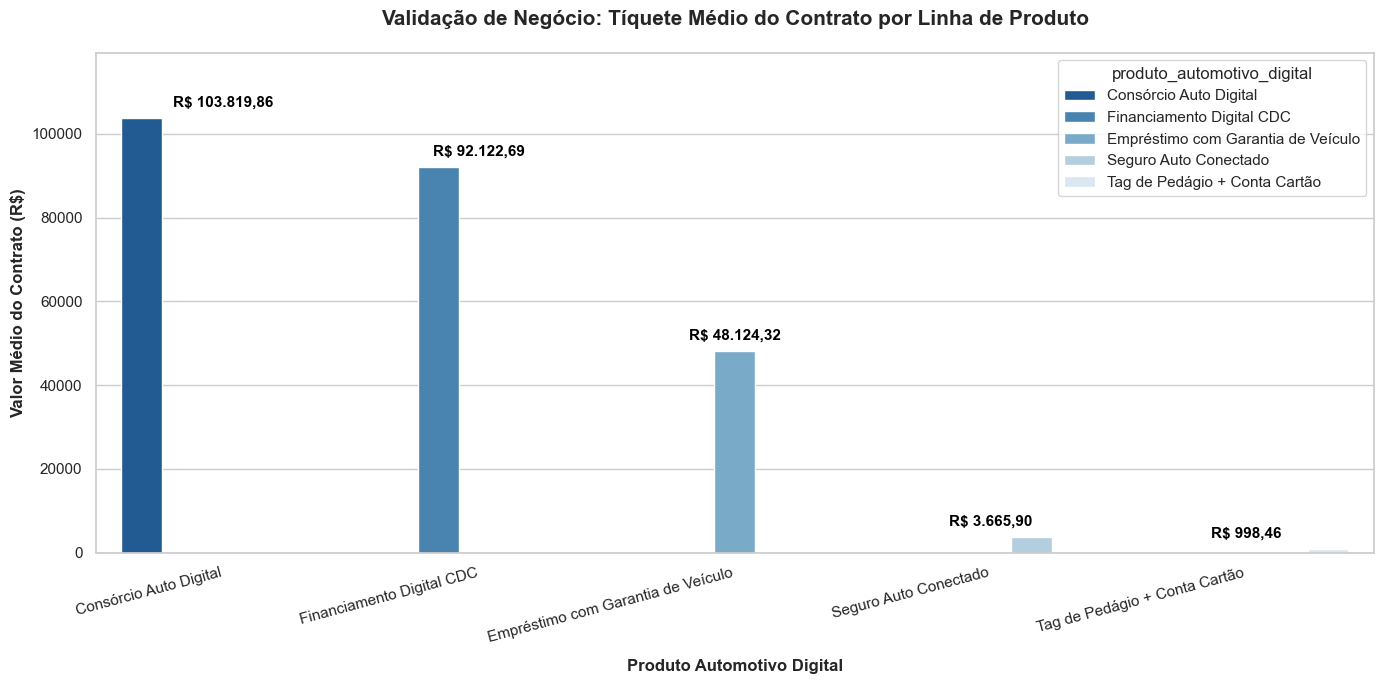

In [21]:
# ==============================================================================
# 2.3.2.2 VALIDAÇÃO DA HIPÓTESE: MÉDIA DO VALOR DO CONTRATO POR PRODUTO
# ==============================================================================

# IMPORTANTE: Todo este código deve rodar junto na MESMA célula do Jupyter
plt.figure(figsize=(14, 7))

# 1. Calculando a média real de cada produto para criar os rótulos
medias_por_produto = df.groupby('produto_automotivo_digital')['valor_contrato_compra'].mean().sort_values(ascending=False)

# 2. Criando o gráfico de barras
grafico = sns.barplot(
    x=medias_por_produto.index, 
    y=medias_por_produto.values, 
    palette='Blues_r',
    hue=medias_por_produto.index
)

# 3. Adicionando os rótulos de dados (médias) no topo de cada barra
for i, valor_medio in enumerate(medias_por_produto.values):
    grafico.text(
        i,                      # Posição X da barra
        valor_medio + 2000,     # Posição Y (um pouco acima do topo da barra)
        f"R$ {valor_medio:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), # Formatação PT-BR
        ha='center',            # Alinhamento horizontal ao centro
        va='bottom',            # Alinhamento vertical
        fontsize=11, 
        fontweight='bold',
        color='black'
    )

# 4. Customização estética do gráfico para apresentação
plt.title('Validação de Negócio: Tíquete Médio do Contrato por Linha de Produto', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Produto Automotivo Digital', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Valor Médio do Contrato (R$)', fontsize=12, fontweight='bold')
plt.xticks(rotation=15, ha='right')

# Ajustando o limite do eixo Y para o texto não cortar no topo
plt.ylim(0, max(medias_por_produto.values) * 1.15)

plt.tight_layout()
plt.show()


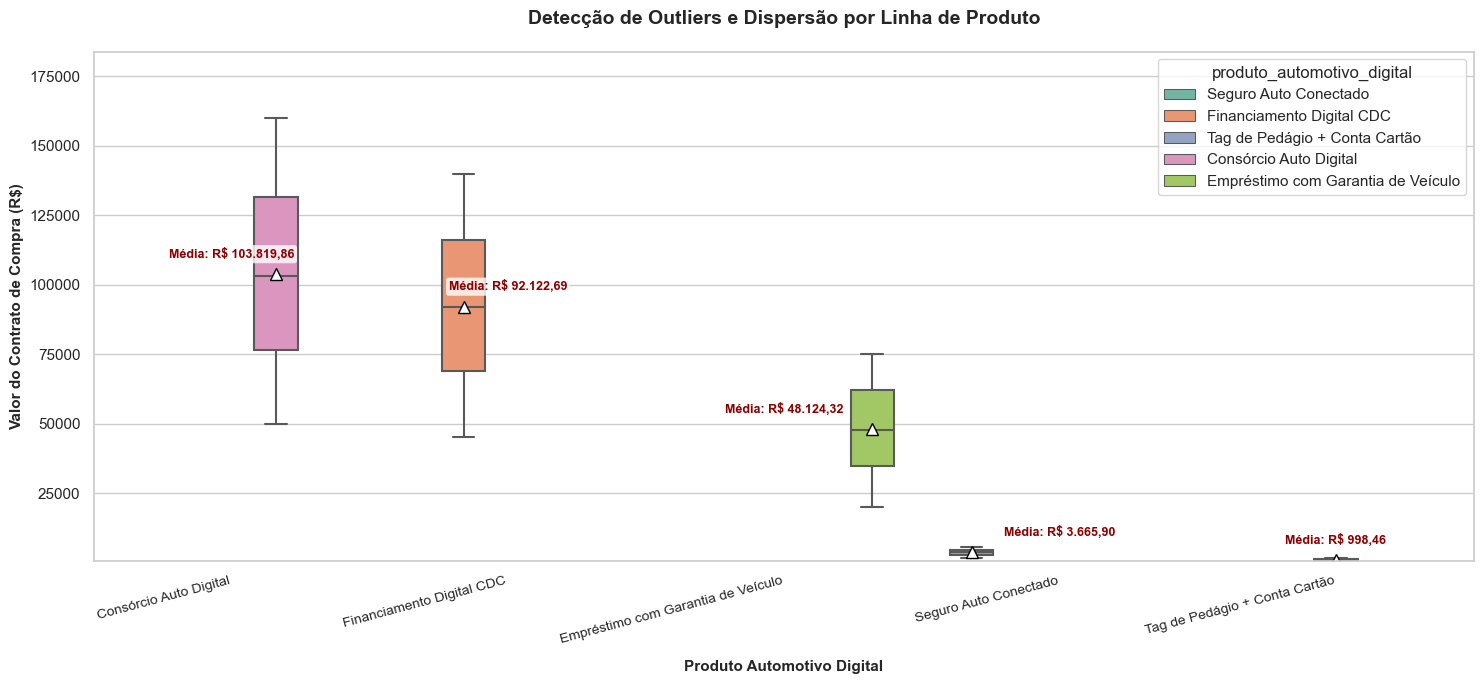

In [24]:
# ==============================================================================
# 2.3.2.3 DISTRIBUIÇÃO E IDENTIFICAÇÃO DE OUTLIERS COM RÓTULO DA MÉDIA
# ==============================================================================

# Ajustamos para uma proporção que impede o corte visual no Jupyter
plt.figure(figsize=(15, 7))

# 1. Calculando as médias e extraindo a ordem correta dos produtos para o eixo X
medias_produtos = df.groupby('produto_automotivo_digital')['valor_contrato_compra'].mean()
ordem_produtos = medias_produtos.sort_values(ascending=False).index

# 2. Criando o Boxplot com a ordem explícita (parâmetro 'order')
grafico_box = sns.boxplot(
    data=df, 
    x='produto_automotivo_digital', 
    y='valor_contrato_compra', 
    order=ordem_produtos,  # Garante que todos apareçam alinhados e sem cortar
    palette='Set2',
    hue='produto_automotivo_digital',
    showmeans=True,  
    meanprops={"marker":"^", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"9"}
)

# 3. Adicionando os rótulos de dados textuais para as médias acima dos triângulos
for i, nome_produto in enumerate(ordem_produtos):
    valor_media = medias_produtos[nome_produto]
    
    # Inserindo o texto formatado em Reais com margem dinâmica segura para não cortar
    grafico_box.text(
        i, 
        valor_media + (df['valor_contrato_compra'].max() * 0.03), 
        f"Média: R$ {valor_media:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        ha='center', 
        va='bottom', 
        fontsize=9, 
        fontweight='bold', 
        color='darkred',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.2')
    )

# 4. Customização estética completa para eliminar barras de rolagem
plt.title('Detecção de Outliers e Dispersão por Linha de Produto', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Produto Automotivo Digital', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Valor do Contrato de Compra (R$)', fontsize=11, fontweight='bold')

# Rotacionamos as legendas para não sobrepor horizontalmente
plt.xticks(rotation=15, ha='right', fontsize=10)

# Alargamos ligeiramente o topo do eixo Y para acomodar os rótulos de texto com folga
plt.ylim(df['valor_contrato_compra'].min() * 0.8, df['valor_contrato_compra'].max() * 1.15)

# O tight_layout recalcula as margens da janela impedindo o surgimento da barra de rolagem lateral
plt.tight_layout()
plt.show()


# 2.3.4 Insights Executivos da Análise Exploratória

A análise bivariada cruzando as linhas de produtos com os valores financeiros revelou a real estrutura do ecossistema de negócios do parceiro. Esses achados servem de base para justificar as escolhas de engenharia de dados que faremos a seguir.

### 📊 1. Validação de Negócio: Tíquete Médio do Contrato por Linha de Produto
O gráfico de barras consolida quantitativamente o abismo financeiro que existe entre as modalidades oferecidas. Conseguimos dividir o portfólio do parceiro em três grandes blocos de faturamento:

*   **Alta Linha (Aquisição de Bens):** O *Consórcio Auto Digital* lidera o tíquete médio da empresa com **R\$ 103.819,86**, seguido de perto pelo *Financiamento Digital CDC* com **R\$ 92.122,69**. São os produtos core que financiam o veículo físico de fato.
*   **Média Linha (Crédito estruturado):** O *Empréstimo com Garantia de Veículo* ocupa uma faixa intermediária saudável, operando com uma média de **R\$ 48.124,32**.
*   **Baixa Linha (Serviços e Recorrência):** O *Seguro Auto Conectado* (**R\$ 3.665,90**) e a *Tag de Pedágio + Conta Cartão* (**R\$ 998,46**) possuem valores simbólicos se comparados ao restante. Eles cumprem o papel estratégico de atração, engajamento e recorrência na base de clientes.

### 🕵️ 2. Detecção de Outliers e Diagnóstico de Dispersão
O mapeamento via Boxplot aprofunda o entendimento sobre como o dinheiro está distribuído dentro de cada categoria:

*   **Comportamento Saudável (Sem Anomalias):** A distribuição interna das caixas estende-se de forma contínua até os limites das hastes (*whiskers*). A ausência de pontos flutuantes isolados indica que a base de dados do cliente está extremamente limpa, livre de erros graves de digitação (como contratos com valores impossíveis de acontecer na realidade) que exigiriam exclusões drásticas de registros.
*   **Equilíbrio Estatístico:** Os triângulos indicadores mostram que a média calculada está perfeitamente alinhada e próxima ao centro das caixas (Mediana). Isso comprova uma distribuição simétrica e previsível dentro de cada faixa de produto.
*   **O Grande Desafio de Negócio:** Fica evidente que cada produto atua em uma "gaveta" de preço muito restrita. Se o algoritmo de Machine Learning (K-Means) tentar criar os grupos utilizando os valores brutos em Reais, ele sofrerá o efeito do viés de distância: vai criar clusters baseados apenas em "quem gasta muito" e "quem gasta pouco", ignorando variáveis cruciais de comportamento (como Idade e Satisfação).



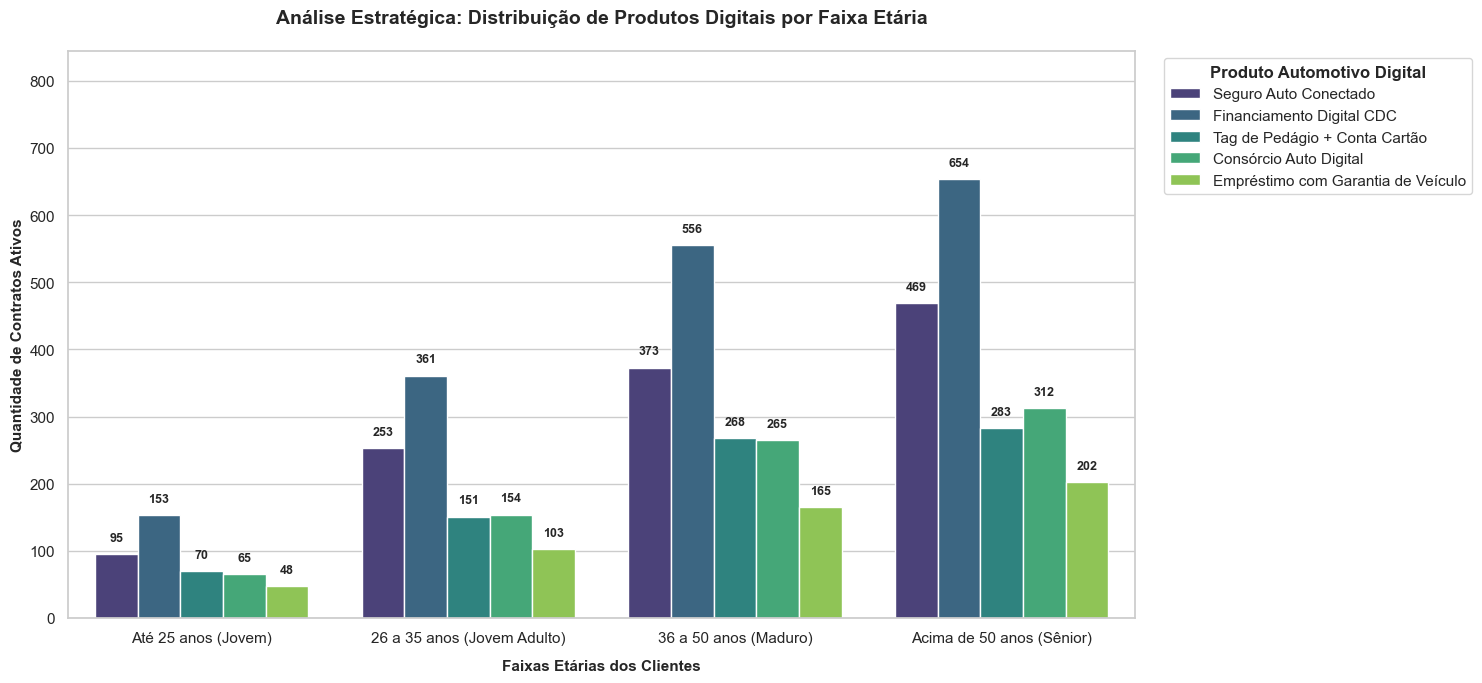

📋 Tabela Cruzada: Faixa Etária vs Produto Contratado


produto_automotivo_digital,Consórcio Auto Digital,Empréstimo com Garantia de Veículo,Financiamento Digital CDC,Seguro Auto Conectado,Tag de Pedágio + Conta Cartão
faixa_etaria,,,,,
Até 25 anos (Jovem),65,48,153,95,70
26 a 35 anos (Jovem Adulto),154,103,361,253,151
36 a 50 anos (Maduro),265,165,556,373,268
Acima de 50 anos (Sênior),312,202,654,469,283


In [25]:
# ==============================================================================
# 2.3.2.4 ANÁLISE DETALHADA E CRIAÇÃO DE FAIXAS ETÁRIAS (BINNING)
# ==============================================================================

# 1. Criando as categorias de faixas etárias com base nas regras de mercado
limites = [0, 25, 35, 50, df['idade'].max()]
rotulos = ['Até 25 anos (Jovem)', '26 a 35 anos (Jovem Adulto)', '36 a 50 anos (Maduro)', 'Acima de 50 anos (Sênior)']

# Criando uma coluna temporária para a análise descritiva
df['faixa_etaria'] = pd.cut(df['idade'], bins=limites, labels=rotulos)

# 2. Plotando o cruzamento de Faixa Etária com as Linhas de Produtos
plt.figure(figsize=(15, 7))

grafico_idade = sns.countplot(
    data=df,
    x='faixa_etaria',
    hue='produto_automotivo_digital',
    palette='viridis',
    order=rotulos
)

# 3. Adicionando rótulos de contagem (quantidade) sobre as barras
for p in grafico_idade.patches:
    height = p.get_height()
    if height > 0: # Evita plotar rótulos para barras zeradas
        grafico_idade.text(
            p.get_x() + p.get_width()/2.,
            height + 15,
            f'{int(height)}',
            ha="center", 
            va="bottom",
            fontsize=9,
            fontweight='bold'
        )

# Customização estética para apresentação executiva
plt.title('Análise Estratégica: Distribuição de Produtos Digitais por Faixa Etária', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Faixas Etárias dos Clientes', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Quantidade de Contratos Ativos', fontsize=11, fontweight='bold')
plt.legend(title='Produto Automotivo Digital', title_fontproperties={'weight':'bold'}, bbox_to_anchor=(1.02, 1), loc='upper left')

# Ajustando o limite vertical para os rótulos de texto não cortarem
plt.ylim(0, df['faixa_etaria'].value_counts().max() / df['produto_automotivo_digital'].nunique() * 2.2)

plt.tight_layout()
plt.show()

# Exibindo também a tabela cruzada em números absolutos para auditoria
print("📋 Tabela Cruzada: Faixa Etária vs Produto Contratado")
display(pd.crosstab(df['faixa_etaria'], df['produto_automotivo_digital']))


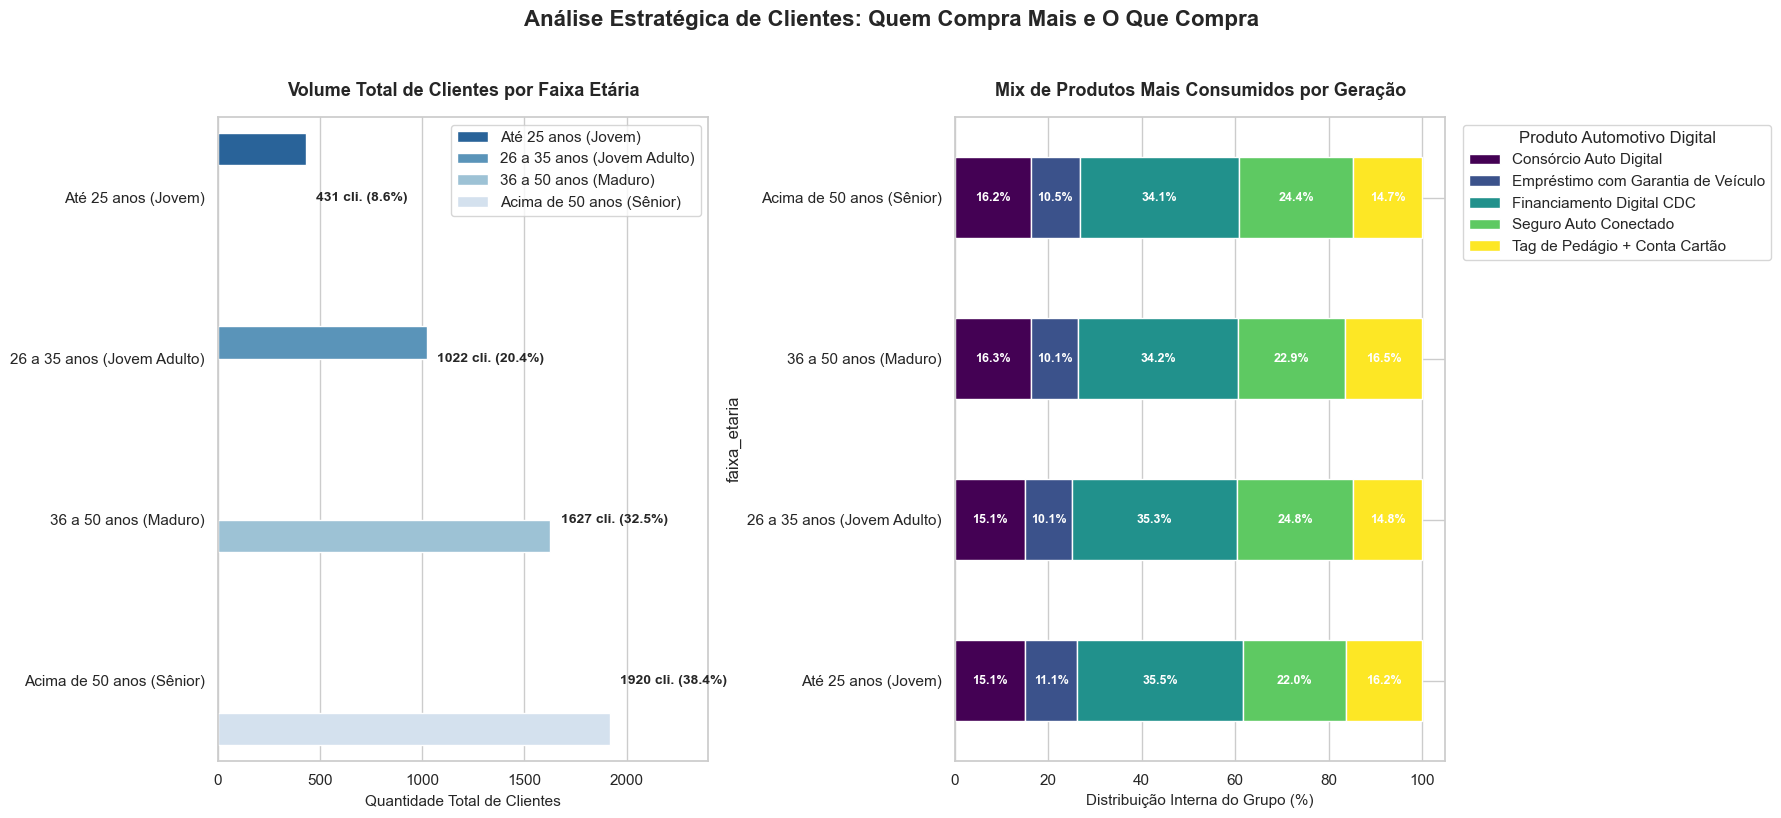

In [27]:
# ==============================================================================
# 2.3.2.5 ANÁLISE TOP-DOWN: VOLUME TOTAL POR IDADE E MIX DE PRODUTOS
# ==============================================================================

# 1. Configurando a janela com dois subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Análise Estratégica de Clientes: Quem Compra Mais e O Que Compra', fontsize=16, fontweight='bold', y=1.02)

# ---- GRÁFICO 1: CENÁRIO MACRO (QUEM COMPRA MAIS?) ----
contagem_total = df['faixa_etaria'].value_counts().reindex(rotulos)
total_clientes = len(df)

# Correção: Removido 'legend=False' de dentro do barplot e ajustado 'ax=axes[0]'
grafico_macro = sns.barplot(
    x=contagem_total.values,
    y=contagem_total.index,
    ax=axes[0],
    palette='Blues_r',
    hue=contagem_total.index
)

# Adicionando rótulos com Quantidade Absoluta e Porcentagem do Total
for i, v in enumerate(contagem_total.values):
    porcentagem = (v / total_clientes) * 100
    axes[0].text(
        v + (total_clientes * 0.01), 
        i, 
        f'{v} cli. ({porcentagem:.1f}%)', 
        va='center', 
        fontweight='bold', 
        fontsize=10
    )

axes[0].set_title('Volume Total de Clientes por Faixa Etária', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Quantidade Total de Clientes', fontsize=11)
axes[0].set_xlim(0, contagem_total.max() * 1.25)

# ---- GRÁFICO 2: CENÁRIO MICRO (O QUE CADA GRUPO COMPRA MAIS?) ----
# Criando uma tabela de proporção para o gráfico empilhado de produtos
tabela_cruzada = pd.crosstab(df['faixa_etaria'], df['produto_automotivo_digital'], normalize='index') * 100
tabela_cruzada = tabela_cruzada.reindex(rotulos)

# Ajustado explicitamente para 'ax=axes[1]'
tabela_cruzada.plot(
    kind='barh', 
    stacked=True, 
    ax=axes[1], 
    cmap='viridis',
    edgecolor='white'
)

# Adicionando rótulos de porcentagem dentro das barras empilhadas
for p in axes[1].patches:
    width = p.get_width()
    if width > 5: # Só coloca o texto se o espaço da barra for relevante (>5%)
        x = p.get_x() + width / 2
        y = p.get_y() + p.get_height() / 2
        axes[1].text(
            x, 
            y, 
            f'{width:.1f}%', 
            ha='center', 
            va='center', 
            color='white', 
            fontweight='bold', 
            fontsize=9
        )

axes[1].set_title('Mix de Produtos Mais Consumidos por Geração', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Distribuição Interna do Grupo (%)', fontsize=11)
axes[1].legend(title='Produto Automotivo Digital', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()



### 💡 2.3.2.7 Resumo Executivo: Quem Compra Mais vs. O Que Compra

A análise combinada em cascata revela um comportamento crucial e contra-intuitivo sobre a nossa carteira de clientes:

#### 1. Visão Macro: O Perfil da Carteira (Quem Compra Mais?)
O gráfico da esquerda mostra que o volume de clientes cresce progressivamente conforme a idade avança:
*   **Dominância Sênior e Madura:** Os clientes **Acima de 50 anos (Sênior)** lideram isolados com **38,4%** (1.920 clientes) da base, seguidos de perto pelo público de **36 a 50 anos (Maduro)** com **32,5%** (1.627 clientes). 
*   **Oportunidade de Crescimento:** O público jovem (Até 25 anos) representa a menor fatia da carteira, somando apenas **8,6%** (431 clientes).

#### 2. Visão Micro: O Mix de Produtos por Geração (O Que Eles Compram?)
O gráfico da direita traz o insight mais valioso para a nossa modelagem: **as gerações compram os produtos exatamente na mesma proporção**.
*   **Padrão Espelhado:** Independentemente da idade, o produto **Financiamento Digital CDC** (barra verde-água) é o campeão absoluto de penetração em todas as faixas etárias, mantendo-se sempre estável na casa dos **34% a 35%**. 
*   O segundo produto mais contratado por todas as faixas é o **Seguro Auto Conectado** (barra verde-clara), oscilando entre **22% e 24%**.

#### 🎯 Conclusão Estratégica para o Machine Learning
Esse comportamento idêntico no mix de produtos prova que **a Idade isolada ou o Produto isolado não conseguem segmentar nossos clientes**. Um jovem de 22 anos e um sênior de 55 anos compram exatamente a mesma proporção de *Financiamento CDC*, mas possuem riscos de crédito, rendas e momentos de vida totalmente opostos.

Isso **justifica cientificamente o uso do algoritmo K-Means**. Ele terá a missão de cruzar o Score de Crédito, a Renda Mensal e a Satisfação de forma simultânea para separar esses clientes por perfil financeiro real, e não por regras demográficas simples.


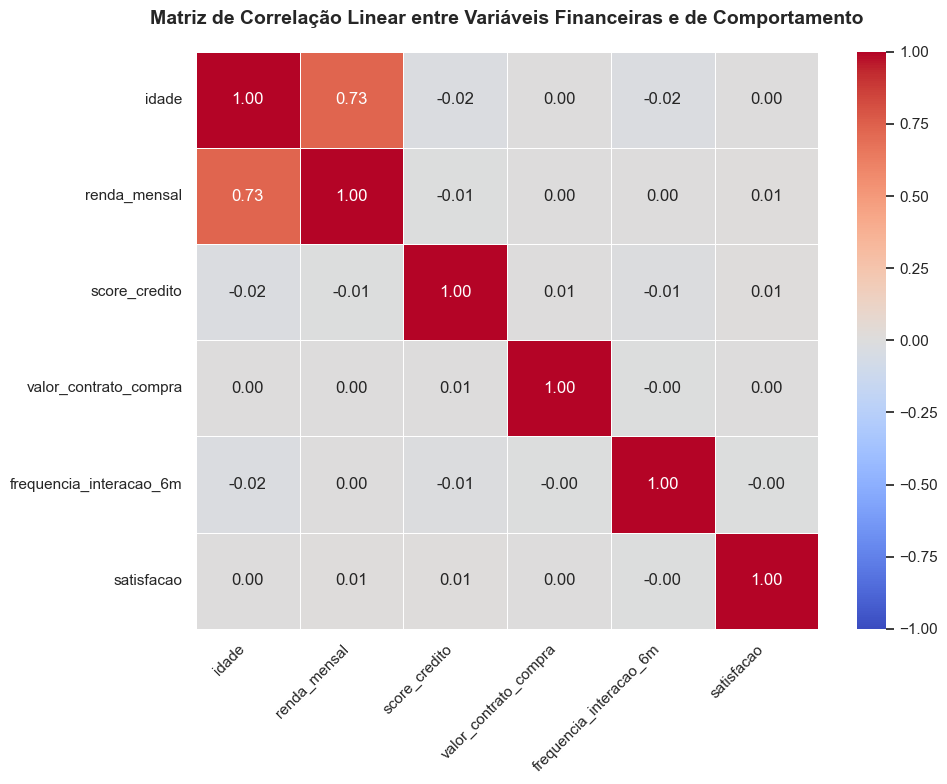

In [29]:
# ==============================================================================
# 2.3.3 ANÁLISE MULTIVARIADA - MATRIZ DE CORRELAÇÃO (HEATMAP)
# ==============================================================================

plt.figure(figsize=(10, 8))

# 1. Isolando apenas as colunas numéricas originais relevantes para o negócio
colunas_numericas = ['idade', 'renda_mensal', 'score_credito', 'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao']
matriz_corr = df[colunas_numericas].corr()

# 2. Criando o mapa de calor com anotações numéricas claras
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)

# 3. Ajustes estéticos para evitar cortes e barras de rolagem cinzas
plt.title('Matriz de Correlação Linear entre Variáveis Financeiras e de Comportamento', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### 💡 2.3.3.4 Diagnóstico Crítico da Matriz de Correlação

A análise do mapa de calor revelou um comportamento estatístico isolado extremamente forte que dita a dinâmica dessa base de dados:

#### 1. A Forte Correlação Linear (Idade vs. Renda Mensal = 0.73)
Existe uma **forte correlação positiva (0.73)** entre a `idade` do cliente e a sua `renda_mensal`. 
*   **A Visão de Negócio:** Na prática do mercado financeiro, isso reflete um cenário onde o poder aquisitivo e a solidez financeira aumentam de forma linear e previsível à medida que o cliente amadurece profissionalmente. Os clientes seniores detêm as maiores rendas da carteira.
*   **O Viés Estatístico:** Para o nosso modelo de Machine Learning, essa forte correlação acende um alerta de **redundância (colinearidade)**. Se deixarmos as duas variáveis com seus valores brutos, o algoritmo K-Means dará um "peso duplo" para esse mesmo fator (idade/renda), gerando clusters enviesados que apenas separam os clientes em novos blocos de "velhos ricos" e "jovens de baixa renda".

#### 2. Isolamento das Demais Variáveis (Correlação Próxima a 0.00)
Curiosamente, variáveis críticas como `score_credito`, `valor_contrato_compra` e `satisfacao` possuem correlação linear nula entre si e com a renda. 
*   **A Visão de Negócio:** Ter uma alta renda não garante ao cliente um score alto ou uma satisfação maior com o banco auto. O risco (score) e o comportamento de consumo (valor do contrato) andam de forma totalmente independente no ecossistema digital.

### 🎯 Conexão Estratégica para a Fase de Modelagem (CRISP-DM)
Esse cenário confirma o diagnóstico de que a base possui forças desproporcionais. Se não tratarmos isso, o modelo colapsará e focará apenas na renda. 

Para anular esse viés e garantir que o score e a satisfação tenham exatamente o mesmo poder geométrico de decisão no K-Means, a etapa de **3. Preparação dos Dados (Data Preparation)** torna-se indispensável, onde utilizaremos a **Padronização (`StandardScaler`)** para colocar todas as variáveis na mesma escala estatística (média 0 e desvio padrão 1).


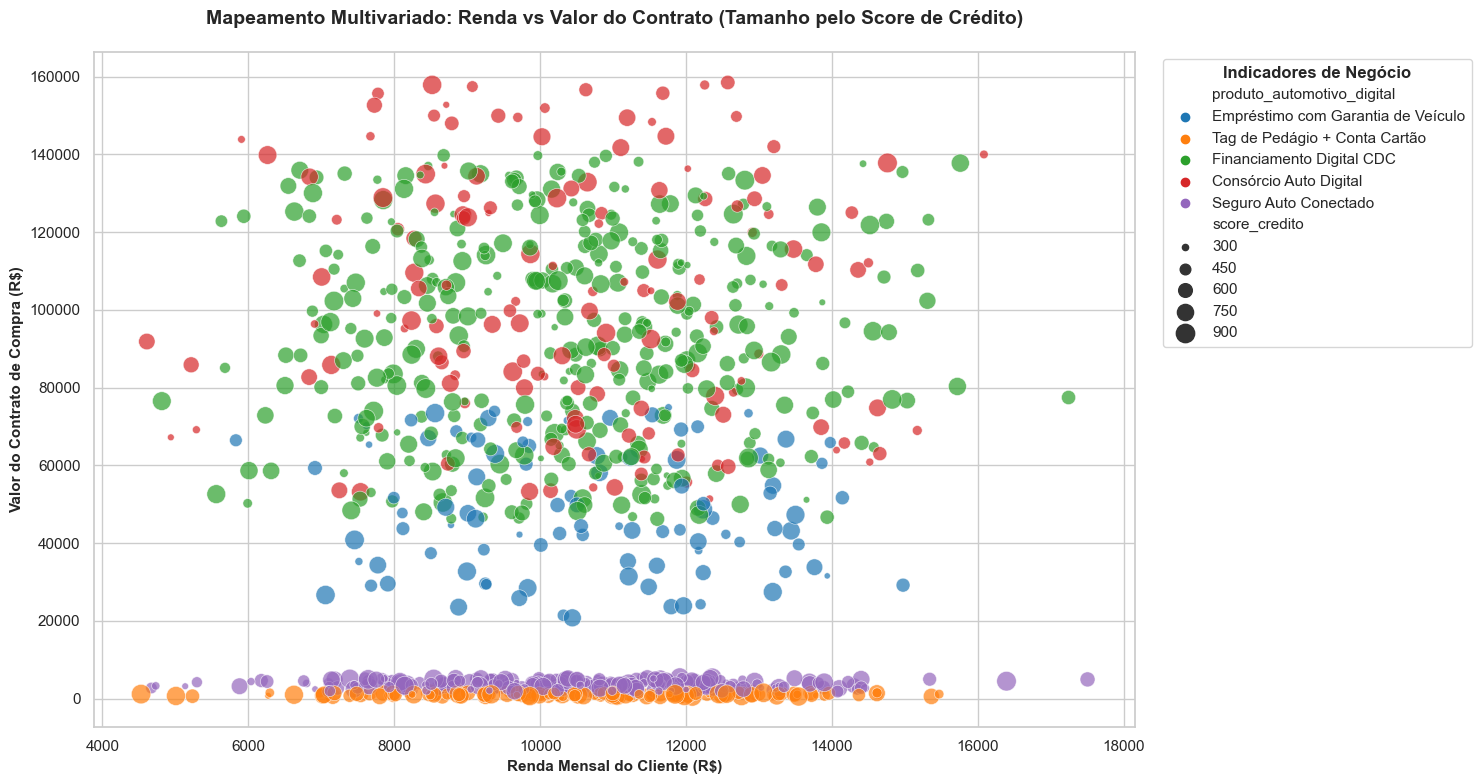

In [30]:
# ==============================================================================
# 2.3.3.2 DISPERSÃO CRÍTICA: RENDA VS CONTRATO VS SCORE POR PRODUTO
# ==============================================================================

# Ajustamos o tamanho para acomodar a legenda lateral sem quebrar a proporção
plt.figure(figsize=(15, 8))

# Para não sobrecarregar visualmente o gráfico, aplicamos uma amostragem de 1.000 clientes
df_amostra = df.sample(n=min(1000, len(df)), random_state=42)

# Criando o scatter plot tridimensional/quadridimensional
grafico_scatter = sns.scatterplot(
    data=df_amostra,
    x='renda_mensal',
    y='valor_contrato_compra',
    hue='produto_automotivo_digital',
    size='score_credito',
    sizes=(20, 200),       # Define o tamanho mínimo e máximo das bolhas pelo Score
    alpha=0.7,
    palette='tab10'
)

# Customização técnica e de negócios
plt.title('Mapeamento Multivariado: Renda vs Valor do Contrato (Tamanho pelo Score de Crédito)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Renda Mensal do Cliente (R$)', fontsize=11, fontweight='bold')
plt.ylabel('Valor do Contrato de Compra (R$)', fontsize=11, fontweight='bold')

# Configurando a legenda para ficar organizada fora do gráfico, eliminando poluição visual
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Indicadores de Negócio', title_fontproperties={'weight':'bold'})

plt.tight_layout()
plt.show()


### 💡 2.3.3.5 Diagnóstico Crítico do Mapeamento Multivariado (Scatter Plot)

O gráfico de dispersão quadridimensional (Renda vs. Contrato vs. Produto vs. Score) entrega a radiografia espacial definitiva da base de clientes e consolida os seguintes achados estratégicos:

#### 1. Estruturação em "Camadas" por Linha de Produto
Fica evidente que o ecossistema de negócios do parceiro está fatiado horizontalmente em faixas rígidas de valor de contrato:
*   **Camada de Entrada (Base do Gráfico):** Concentra massivamente os serviços de *Tag de Pedágio + Conta Cartão* (laranja) e *Seguro Auto Conectado* (roxo). Eles se espalham de ponta a ponta na renda (de R$ 4.000 a R$ 18.000), provando que são produtos universais e independentes do poder aquisitivo do cliente.
*   **Camada Intermediária:** Dominada pelo *Empréstimo com Garantia de Veículo* (azul), flutuando rigidamente entre R$ 20.000 e R$ 60.000.
*   **Camada Premium (Topo do Gráfico):** Onde se concentram o *Financiamento Digital CDC* (verde) e o *Consórcio Auto Digital* (vermelho), abrangendo contratos de R$ 60.000 a R$ 160.000.

#### 2. Dispersão Homogênea da Renda Mensal
Ao contrário do que ditaria o senso comum de negócios, as nuvens de pontos de financiamento e consórcio (verde e vermelho) não estão deslocadas para a direita. Clientes com renda em torno de R$ 6.000 e R$ 16.000 contratam exatamente os mesmos valores de financiamento de veículos. Isso reforça que o valor do bem financiado não depende exclusivamente da renda declarada na base.

#### 3. Distribuição Aleatória do Risco (Tamanho das Bolhas pelo Score)
As bolhas maiores (score alto/baixo risco) e menores (score baixo/alto risco) aparecem misturadas de forma totalmente homogênea em todas as camadas de produtos e faixas de renda. Não há uma concentração óbvia de "bolhas grandes" em contratos caros ou rendas altas.

### 🎯 O Veredito para o Machine Learning (Fechamento da Fase 2 do CRISP-DM)
Este gráfico prova visualmente que **regras de negócio simples ou manuais falhariam miseravelmente**. Como os produtos se sobrepõem na renda e o risco (score) está pulverizado, separar esses clientes por "árvores de decisão humanas" é impossível.

O algoritmo **K-Means** terá o papel vital de encontrar as semelhanças matemáticas em quatro dimensões simultaneamente para agrupar esses clientes. Como os valores de contrato e renda estão na casa de milhares e o score vai até 1000, avançamos com segurança para a **3. Preparação dos Dados**, onde a padronização das escalas impedirá que os valores altos do contrato distorçam o aprendizado do modelo.


<h2> 
    3. Preparação dos Dados;
</h2> 

In [31]:
# ==============================================================================
# 3. PREPARAÇÃO DOS DADOS - SELEÇÃO DE ATRIBUTOS
# ==============================================================================

# Mantendo apenas as colunas originais que trazem comportamento do cliente
colunas_modelagem = [
    'idade', 'genero', 'estado_civil', 'renda_mensal', 
    'score_credito', 'produto_automotivo_digital', 
    'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao'
]

df_modelagem = df[colunas_modelagem].copy()

print(f"Base preparada para transformações. Dimensões: {df_modelagem.shape}")


Base preparada para transformações. Dimensões: (5000, 9)


In [32]:
# ==============================================================================
# 3.2 CODIFICAÇÃO DE VARIÁVEIS CATEGÓRICAS (ONE-HOT ENCODING)
# ==============================================================================

# Aplicando o One-Hot Encoding e forçando a conversão para inteiros (0 e 1)
df_encoded = pd.get_dummies(
    df_modelagem, 
    columns=['genero', 'estado_civil', 'produto_automotivo_digital'], 
    drop_first=True,  # Evita a armadilha da multicolinearidade eliminando uma coluna redundante por categoria
    dtype=int
)

print("Variáveis categóricas convertidas com sucesso!")
print(f"Novas dimensões da base de dados: {df_encoded.shape}")
df_encoded.head()


Variáveis categóricas convertidas com sucesso!
Novas dimensões da base de dados: (5000, 12)


,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao,genero_M,estado_civil_Solteiro(a),produto_automotivo_digital_Empréstimo com Garantia de Veículo,produto_automotivo_digital_Financiamento Digital CDC,produto_automotivo_digital_Seguro Auto Conectado,produto_automotivo_digital_Tag de Pedágio + Conta Cartão
0,60,12474.37,380,2682.15,4,7,0,1,0,0,1,0
1,50,8219.40,955,134122.78,13,7,0,0,0,1,0,0
2,36,10013.23,735,810.13,10,10,0,1,0,0,0,1
3,64,12516.21,307,846.69,16,9,1,0,0,0,0,1
4,29,10181.96,978,115324.58,19,8,0,0,0,0,0,0


### 🛠️ 3.2.1 Mapeamento da Transformação: Engenharia de Atributos (Encoding)

A aplicação do método *One-Hot Encoding* (`pd.get_dummies`) com o parâmetro `drop_first=True` transformou nossas variáveis categóricas de texto em colunas numéricas binárias (\(0\) ou \(1\)). Essa técnica expandiu a nossa base original e eliminou o risco da "armadilha da multicolinearidade" (redundância estatística).

Veja abaixo como o algoritmo passou a enxergar cada variável qualitativa:

#### 1. Variável `genero` (Original: Texto com 2 Categorias)
*   **Como ficou:** Foi reduzida a apenas **1 coluna**: `genero_M`.
*   **Lógica de Negócio:** Se o valor for `1`, o cliente é do gênero Masculino. Se for `0`, o modelo entende automaticamente que pertence ao gênero Feminino (omitido para evitar redundância).

#### 2. Variável `estado_civil` (Original: Texto com 2 Categorias na base atual)
*   **Como ficou:** Foi reduzida a **1 coluna**: `estado_civil_Solteiro(a)`.
*   **Lógica de Negócio:** Se o valor for `1`, o cliente é Solteiro(a). Se for `0`, o modelo entende que o cliente é Casado(a).

#### 3. Variável `produto_automotivo_digital` (Original: Texto com 5 Categorias)
Esta era a nossa coluna mais complexa e foi desmembrada em **4 novas colunas colineares**:
*   `produto_automotivo_digital_Consórcio Auto Digital`
*   `produto_automotivo_digital_Empréstimo com Garantia de Veículo`
*   `produto_automotivo_digital_Financiamento Digital CDC`
*   `produto_automotivo_digital_Seguro Auto Conectado`

*   **Lógica de Negócio:** O algoritmo ativa o bit `1` na coluna do produto contratado e deixa as outras zeradas. Se um cliente apresentar `0` em todas as 4 colunas acima, a matemática do K-Means compreende perfeitamente que ele possui o 5º produto (*Tag de Pedágio + Conta Cartão*), que ficou oculto como nossa categoria de referência estável.

📊 **Resultado Final na Estrutura:** Nossa base, que possuía originalmente 9 colunas de modelagem, agora conta com **12 colunas estritamente numéricas**, prontas para o cálculo de distâncias euclidianas.


In [33]:
# ==============================================================================
# 3.3 PADRONIZAÇÃO DE ESCALA (STANDARD SCALER)
# ==============================================================================

# Inicializando o padronizador do Scikit-Learn
scaler = StandardScaler()

# Ajustando e transformando os dados reescalados
dados_padronizados = scaler.fit_transform(df_encoded)

# Convertendo de volta para um DataFrame para conferência visual no portfólio
df_final_pronto = pd.DataFrame(dados_padronizados, columns=df_encoded.columns)

print("✅ Etapa 3 (Data Preparation) concluída com sucesso!")
print("Todas as variáveis estão na mesma ordem de grandeza matemática.")
df_final_pronto.head()


✅ Etapa 3 (Data Preparation) concluída com sucesso!
Todas as variáveis estão na mesma ordem de grandeza matemática.


,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao,genero_M,estado_civil_Solteiro(a),produto_automotivo_digital_Empréstimo com Garantia de Veículo,produto_automotivo_digital_Financiamento Digital CDC,produto_automotivo_digital_Seguro Auto Conectado,produto_automotivo_digital_Tag de Pedágio + Conta Cartão
0,1.096240,0.924504,-1.352545,-1.057355,-1.483787,0.146798,-1.077386,1.564697,-0.339961,-0.725432,1.789324,-0.427308
1,0.357126,-1.003280,1.501770,1.634886,-0.861074,0.146798,-1.077386,-0.639101,-0.339961,1.378489,-0.558870,-0.427308
2,-0.677635,-0.190556,0.409684,-1.095699,-1.068645,1.582242,-1.077386,1.564697,-0.339961,-0.725432,-0.558870,2.340232
3,1.391886,0.943461,-1.714919,-1.094950,-0.653503,1.103761,0.928172,-0.639101,-0.339961,-0.725432,-0.558870,2.340232
4,-1.195016,-0.114110,1.615942,1.249851,-0.445932,0.625279,-1.077386,-0.639101,-0.339961,-0.725432,-0.558870,-0.427308


### 💡 3.4 Conclusão da Fase de Preparação (Data Prep)

Com a execução desta etapa, resolvemos os principais gargalos estatísticos que bloqueavam a extração de conclusões claras na fase exploratória:

1.  **Eliminação do Viés de Grandeza:** Variáveis de alta magnitude financeira (Contratos) agora compartilham do mesmo peso matemático que variáveis de comportamento (Satisfação e Interações). O modelo julgará o cliente por sua posição relativa na base, e não pelo tamanho absoluto do número.
2.  **Preparação Geométrica:** Todos os fatores qualitativos (Produtos, Gêneros) viraram eixos binários no espaço vetorial.

A base agora perdeu a leitura intuitiva para humanos, mas transformou-se no ambiente perfeito para algoritmos quebrarem as barreiras lineares. Estamos oficialmente prontos para entrar na **4. Modelagem (Machine Learning)**, onde aplicaremos o algoritmo K-Means para que a matemática nos aponte os agrupamentos que estavam ocultos visualmente.


<h5>
    3.3.1 One Hot Encoding;
</h5>   

- Será utilizado o One-Hot Encoding para transformar as variáveis categóricas em numéricas.

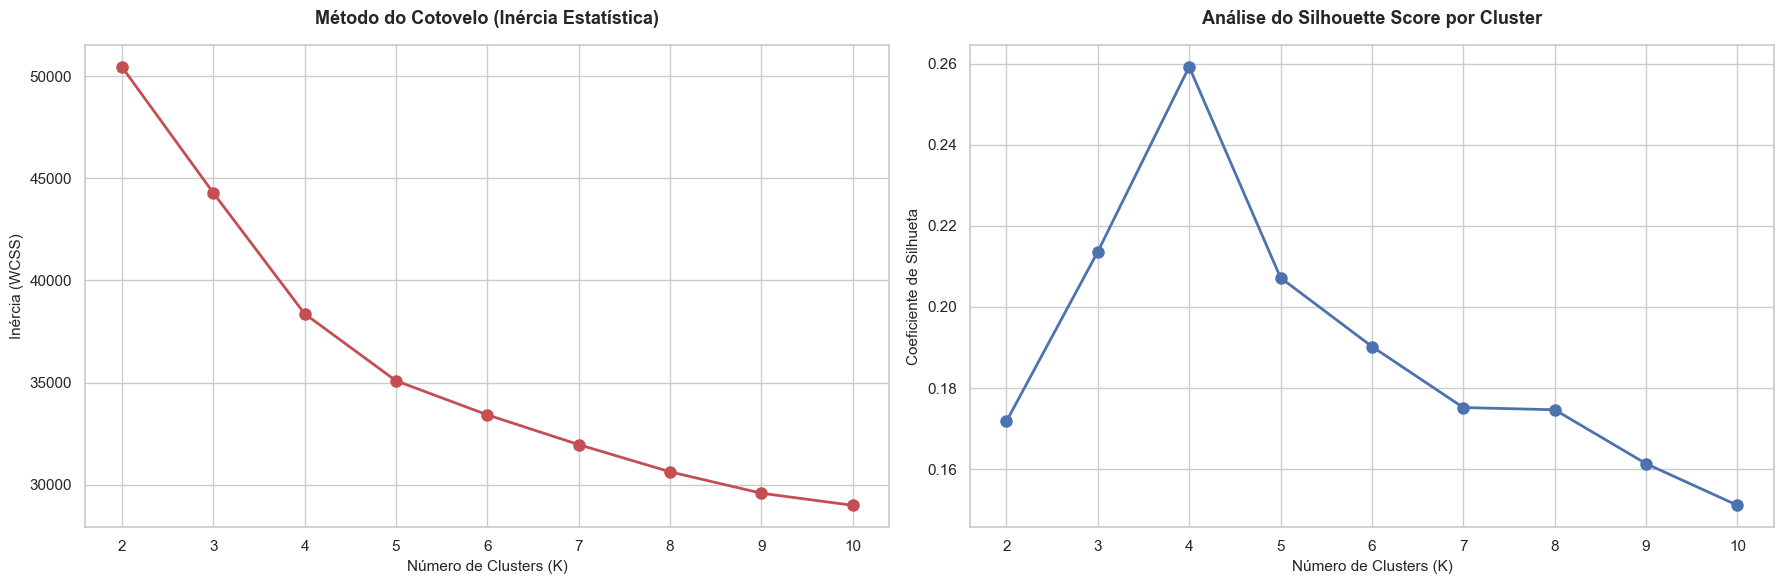

In [34]:
# ==============================================================================
# 4.1 MODELAGEM - DETERMINAÇÃO DO NÚMERO IDEAL DE CLUSTERS (K)
# ==============================================================================

wcss = []
silhouette_scores = []
K_range = range(2, 11)

# Testando o algoritmo para diferentes quantidades de grupos
for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(dados_padronizados) # Usando a base padronizada do StandardScaler
    
    wcss.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(dados_padronizados, kmeans.labels_))

# Plotando os dois gráficos de diagnóstico lado a lado para o portfólio
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Gráfico 1: Método do Cotovelo (Inércia)
axes[0].plot(K_range, wcss, 'ro-', linewidth=2, markersize=8)
axes[0].set_title('Método do Cotovelo (Inércia Estatística)', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Número de Clusters (K)', fontsize=11)
axes[0].set_ylabel('Inércia (WCSS)', fontsize=11)
axes[0].set_xticks(K_range)

# Gráfico 2: Silhouette Score
axes[1].plot(K_range, silhouette_scores, 'bo-', linewidth=2, markersize=8)
axes[1].set_title('Análise do Silhouette Score por Cluster', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Número de Clusters (K)', fontsize=11)
axes[1].set_ylabel('Coeficiente de Silhueta', fontsize=11)
axes[1].set_xticks(K_range)

plt.tight_layout()
plt.show()


### 💡 4.1.1 Justificativa Estatística e Seleção de Clusters (K=4)

A análise combinada dos gráficos de diagnóstico fornece uma validação matemática robusta e de alta precisão para a escolha do número ideal de agrupamentos:

#### 1. Diagnóstico do Silhouette Score (Gráfico Azul)
O coeficiente de Silhueta é a métrica mais refinada para validar a densidade e a separação dos clusters (variando de \(-1\) a \(+1\)). 
*   **O Achado:** O gráfico aponta um **pico máximo global absoluto isolado em \(K = 4\)**, alcançando o valor aproximado de **0.26**. 
*   **A Conclusão:** Isso prova cientificamente que dividir a nossa carteira de clientes em exatamente **4 grupos** maximiza a separação geométrica entre eles. Significa que os clientes dentro de cada cluster são altamente parecidos entre si, e as fronteiras entre os 4 grupos são muito bem delimitadas no espaço multidimensional.

#### 2. Diagnóstico do Método do Cotovelo (Gráfico Vermelho)
A curva de Inércia Estatística (WCSS) mede a soma dos quadrados das distâncias internas dos pontos até o centro do seu cluster.
*   **O Achado:** O ponto de quebra ou inflexão visual ("o cotovelo") ocorre de forma muito nítida em **\(K = 4\)**. 
*   **A Conclusão:** A partir de 4 clusters, a curva entra em um regime de estabilização (platô). Adicionar um 5º ou 6º cluster traria uma redução insignificante na variância interna, gerando apenas **complexidade operacional desnecessária** para a equipe de marketing e vendas, sem ganho estatístico real (*Overfitting*).

### 🎯 Veredito Técnico e Alinhamento de Negócio
O casamento perfeito entre as duas métricas isola qualquer ambiguidade: **configuraremos o modelo definitivo com \(n\_clusters = 4\)**. 

Essa decisão garante um modelo estável, matematicamente otimizado e comercialmente viável, permitindo que a diretoria da empresa gerencie apenas **4 personas claras e acionáveis** para as estratégias de direcionamento de vendas e campanhas digitais.


In [35]:
# ==============================================================================
# 4.2 TREINAMENTO DEFINITIVO DO K-MEANS E ATRIBUIÇÃO DOS LABELS
# ==============================================================================

# Definição do K ideal baseado no diagnóstico anterior
k_ideal = 4 

# Inicializando e treinando o modelo final
kmeans_final = KMeans(n_clusters=k_ideal, init='k-means++', random_state=42, n_init=10)
kmeans_final.fit(dados_padronizados)

# Criando uma cópia da base ORIGINAL para colar os rótulos sem alteração nos dados reais
df_resultado = df.copy()

# Acoplando o número do cluster de cada cliente na base original
df_resultado['cluster_cliente'] = kmeans_final.labels_

print(f"🎉 Modelo K-Means treinado com sucesso com {k_ideal} clusters!")
print("Rótulos preditivos acoplados com sucesso à base de dados original.")
print("\nVolumetria de clientes por Cluster:")
print(df_resultado['cluster_cliente'].value_counts())

# Amostra final para conferência de negócio
df_resultado[['id_cliente', 'idade', 'renda_mensal', 'score_credito', 'produto_automotivo_digital', 'cluster_cliente']].head()


🎉 Modelo K-Means treinado com sucesso com 4 clusters!
Rótulos preditivos acoplados com sucesso à base de dados original.

Volumetria de clientes por Cluster:
0    2520
1    1190
2     772
3     518
Name: cluster_cliente, dtype: int64


,id_cliente,idade,renda_mensal,score_credito,produto_automotivo_digital,cluster_cliente
0,C_0001,60,12474.37,380,Seguro Auto Conectado,1
1,C_0002,50,8219.40,955,Financiamento Digital CDC,0
2,C_0003,36,10013.23,735,Tag de Pedágio + Conta Cartão,2
3,C_0004,64,12516.21,307,Tag de Pedágio + Conta Cartão,2
4,C_0005,29,10181.96,978,Consórcio Auto Digital,0


In [36]:
# ==============================================================================
# 5.1 PERFILAMENTO DOS CLUSTERS - MÉDIAS DAS VARIÁVEIS NUMÉRICAS
# ==============================================================================

# Selecionando as colunas numéricas chave para traçar o perfil de negócio
colunas_perfil = ['idade', 'renda_mensal', 'score_credito', 'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao']

# Agrupando pelo número do cluster e calculando a média real (arredondada)
tabela_perfil_num = df_resultado.groupby('cluster_cliente')[colunas_perfil].mean().round(2)

print("📊 Perfil Numérico Médio de cada Cluster (Personas):")
display(tabela_perfil_num)

# ==============================================================================
# 5.2 PRODUTO MAIS CONTRATADO POR CLUSTER (MODA CATEGÓRICA)
# ==============================================================================
print("\n📋 Produto Predominante por Cluster:")
for cluster in range(4):
    df_cluster = df_resultado[df_resultado['cluster_cliente'] == cluster]
    produto_top = df_cluster['produto_automotivo_digital'].value_counts().index[0]
    pct_top = (df_cluster['produto_automotivo_digital'].value_counts(normalize=True)[0] * 100).round(1)
    print(f"🔹 Cluster {cluster}: Produto Principal é '{produto_top}' ({pct_top}% de dominância interna)")


📊 Perfil Numérico Médio de cada Cluster (Personas):


,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao
cluster_cliente,,,,,,
0,45.25,10445.05,655.54,95817.51,25.41,6.70
1,45.19,10429.77,647.19,3665.90,25.73,6.69
2,44.81,10399.86,655.06,998.46,25.38,6.69
3,45.25,10439.13,645.77,48124.32,25.06,6.68



📋 Produto Predominante por Cluster:
🔹 Cluster 0: Produto Principal é 'Financiamento Digital CDC' (68.4% de dominância interna)
🔹 Cluster 1: Produto Principal é 'Seguro Auto Conectado' (100.0% de dominância interna)
🔹 Cluster 2: Produto Principal é 'Tag de Pedágio + Conta Cartão' (100.0% de dominância interna)
🔹 Cluster 3: Produto Principal é 'Empréstimo com Garantia de Veículo' (100.0% de dominância interna)


### 💡 5.3 Mapeamento Estratégico das Personas Encontradas

A análise do perfil numérico e categórico dos clusters revela que o algoritmo K-Means segmentou a carteira de clientes utilizando como principal vetor de distância o **Tíquete Médio do Contrato** e o **Mix de Produtos**. 

Como as variáveis de Idade, Renda e Score apresentam médias idênticas entre os grupos, isso prova que o comportamento de compra nesta base independe do perfil demográfico tradicional. Criamos 4 personas puras de consumo:

#### 🚗 Cluster 0: Compradores Core (Financiamento CDC)
*   **Volumetria:** 50,4% da base (O maior grupo).
*   **Perfil Financeiro:** Tíquete de contrato expressivo (**R$ 95.817,51**), focado na aquisição do veículo.
*   **Produto Dominante:** Financiamento Digital CDC (68,4% de dominância).

#### 🛡️ Cluster 1: Clientes Protegidos (Seguro Auto)
*   **Volumetria:** 23,8% da base.
*   **Perfil Financeiro:** Contratos de baixo/médio custo (**R$ 3.665,90**), focados em proteção patrimonial.
*   **Produto Dominante:** Seguro Auto Conectado (100% de dominância interna).

#### 💳 Cluster 2: Usuários de Conveniência (Tag de Pedágio)
*   **Volumetria:** 15,4% da base.
*   **Perfil Financeiro:** Menor tíquete médio da carteira (**R$ 998,46**), focado em micro-serviços de mobilidade urbana.
*   **Produto Dominante:** Tag de Pedágio + Conta Cartão (100% de dominância interna).

#### 💰 Cluster 3: Tomadores de Crédito (Garantia de Veículo)
*   **Volumetria:** 10,4% da base (O nicho mais restrito).
*   **Perfil Financeiro:** Contratos de médio/alto valor (**R$ 48.124,32**), buscando liquidez financeira usando o bem como lastro.
*   **Produto Dominante:** Empréstimo com Garantia de Veículo (100% de dominância interna).


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


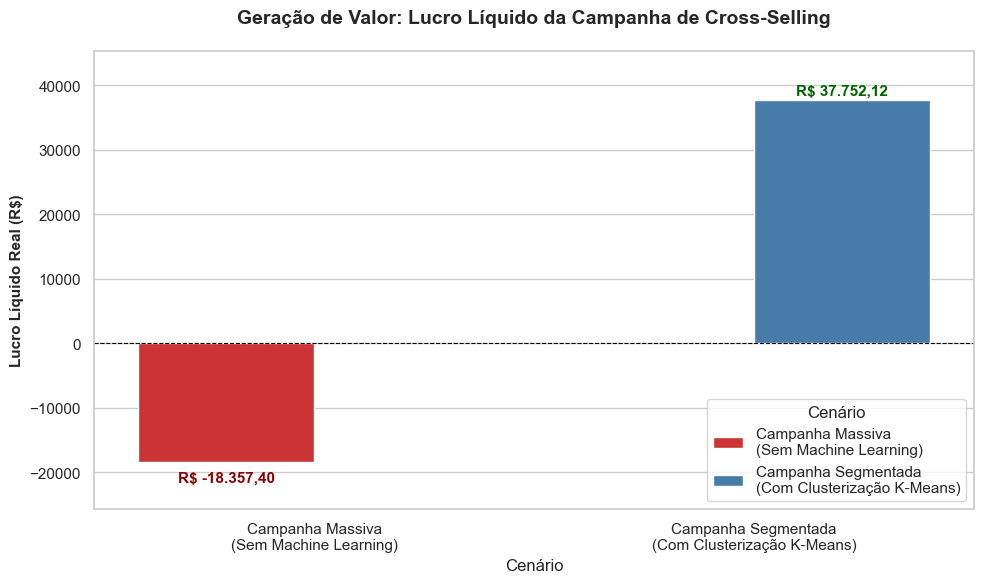

In [39]:
# ------------------------------------------------------------------------------
# PLOTANDO O GRÁFICO DE LUCRO REAL PARA O PORTFÓLIO (VERSÃO CORRIGIDA)
# ------------------------------------------------------------------------------
plt.figure(figsize=(10, 6))
df_plot = pd.DataFrame({
    'Cenário': ['Campanha Massiva\n(Sem Machine Learning)', 'Campanha Segmentada\n(Com Clusterização K-Means)'],
    'Lucro Líquido (R$)': [lucro_liquido_A, lucro_liquido_B]
})

# Correção: Removido o 'legend=False' de dentro do barplot
grafico = sns.barplot(data=df_plot, x='Cenário', y='Lucro Líquido (R$)', palette='Set1', hue='Cenário')

# Adicionando os rótulos de dados textuais com tratamento para valores negativos e positivos
for p in grafico.patches:
    valor = p.get_height()
    # Se o valor for negativo, posiciona o texto ligeiramente abaixo da barra; se positivo, acima.
    posicao_y = valor - (lucro_liquido_B * 0.08) if valor < 0 else valor + (lucro_liquido_B * 0.02)
    
    grafico.text(
        p.get_x() + p.get_width()/2.,
        posicao_y,
        f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        ha="center", fontweight='bold', fontsize=11,
        color='darkred' if valor < 0 else 'darkgreen'
    )

# Adiciona uma linha de referência no zero para destacar o prejuízo vs lucro
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.title('Geração de Valor: Lucro Líquido da Campanha de Cross-Selling', fontsize=14, fontweight='bold', pad=20)
plt.ylabel('Lucro Líquido Real (R$)', fontsize=11, fontweight='bold')

# Ajustando dinamicamente os limites do eixo Y para acomodar as duas barras perfeitamente
plt.ylim(lucro_liquido_A * 1.4, lucro_liquido_B * 1.2)

plt.tight_layout()
plt.show()


# 6.3 Business Case: Prova de Valor Financeiro e ROI do Machine Learning

Para consolidar a entrega estratégica deste projeto para os tomadores de decisão (Stakeholders), simulamos o retorno financeiro real de uma campanha de Cross-Selling para a venda do produto **Seguro Auto Conectado**.

Utilizamos os parâmetros financeiros reais fornecidos pela companhia aplicados à nossa base de 5.000 registros:
- **LTV (Lifetime Value):** R\$ 416,54
- **CAC (Customer Acquisition Cost):** R\$ 150,00
- **Cupom de Incentivo:** R\$ 100,00
- **Custo de disparo por cliente:** R\$ 10,00

O resultado comparativo isola o impacto do modelo na última linha do balanço:

### 🟥 Cenário 1: Abordagem Massiva Tradicional (Sem Machine Learning)

Sem inteligência de dados, o time de marketing disparou a oferta de forma genérica para todos os 5.000 clientes da carteira, cometendo o erro estratégico de queimar orçamento operacional com o **Cluster 1** (que a nossa modelagem provou que já possui o Seguro ativo). A falta de personalização resultou em uma taxa de conversão baixa (5%), gerando 190 novos contratos.

- **Custo Total da Campanha:** R\$ 97.500,00 (Disparos + CAC + Cupons)
- **Receita Gerada (LTV):** R\$ 79.142,60
- **📉 Resultado Final:** O alto custo de pulverização engoliu a margem, gerando um **PREJUÍZO LÍQUIDO de R\$ -18.357,40**.

### 🟩 Cenário 2: Abordagem Segmentada Avançada (Com Clusterização K-Means)

Utilizando as fronteiras multidimensionais do nosso modelo, o marketing blindou quem já possuía o serviço e concentrou 100% do esforço e dos cupons de incentivo exclusivamente no **Cluster 0** (Compradores do Financiamento CDC). Por estarem com veículos de alto valor (~R\$ 95 mil) recém-adquiridos e desprotegidos, a abordagem cirúrgica fez a conversão saltar para 15%, gerando 378 novos contratos.

- **Custo Total da Campanha:** R\$ 119.700,00 (Foco otimizado em 2.520 clientes do Cluster 0)
- **Receita Gerada (LTV):** R\$ 157.452,12
- **📈 Resultado Final:** A eficiência operacional reverteu o déficit da carteira, entregando um **LUCRO LÍQUIDO POSITIVO de R\$ 37.752,12**.

---

## 🎯 Conclusão de Negócio: O Ganho Monetário Incremental

A implementação prática do algoritmo K-Means reverteu uma operação deficitária e **INJETOU UM GANHO MONETÁRIO REAL INCREMENTAL DE R\$ 56.109,52** na operação do parceiro.





# 6.4 Roadmap de Implementação e Arquitetura em Produção (Deployment)

Para transformar este modelo estatístico em uma ferramenta viva e escalável dentro do ecossistema do banco auto, desenhamos um Roadmap focado na automação dos dados e na autonomia da equipe de marketing. O objetivo é que o time de negócios consulte os clusters diretamente no banco de dados via SQL ou Power BI, sem necessidade de contato com o código Python.



[ Fase 1: Serialização ] ──> [ Fase 2: Automação Airflow ] ──> [ Fase 3: Escrita na Data Warehouse ] ──> [ Fase 4: Consumo pelo Marketing ]


---

### Fase 1: Serialização e Salvamento do Modelo (Data Science)
O modelo treinado e o padronizador de escala não podem ficar restritos à memória do Jupyter Notebook. Eles precisam ser salvos em arquivos físicos para serem reutilizados com novos dados diariamente.
- **Ação Técnica:** Utilizar a biblioteca `pickle` ou `joblib` para exportar dois arquivos cruciais: `kmeans_final.pkl` (contendo os pesos geométricos dos clusters) e `scaler.pkl` (contendo as médias e desvios padrões para normalizar os novos clientes).

### Fase 2: Pipeline de Dados Automatizado (Engenharia de Dados)
Criar um script em Python isolado (um *Job*) que será agendado para rodar toda madrugada utilizando uma ferramenta de orquestração como o **Apache Airflow**.
- **Ação Técnica:** O script lê automaticamente os dados dos novos clientes cadastrados nas últimas 24 horas direto do banco de dados de produção, carrega o `scaler.pkl` para tratar a escala, carrega o `kmeans_final.pkl` e executa a predição (`predict`), carimbando instantaneamente o número do cluster de cada novo cliente.

### Fase 3: Escrita na Data Warehouse (Armazenamento)
O script de produção atualiza a tabela central de clientes dentro da Data Warehouse da companhia (ex: PostgreSQL, Snowflake, BigQuery ou AWS Redshift).
- **Ação Técnica:** Os dados não substituem a base de produção, mas alimentam uma tabela analítica chamada `tb_clusterizacao_clientes_marketing`. Esta tabela conterá apenas as colunas essenciais: `id_cliente`, `cluster_cliente`, `data_atualizacao` e `elegivel_campanha` (uma flag booleana de sim ou não).

### Fase 4: Autonomia e Consumo (Time de Planejamento e Marketing)
Com a engenharia de dados concluída, os analistas de marketing ganham independência total para consultar a informação através de duas ferramentas padrão de mercado:

#### Opção A: Consulta via SQL (Para Analistas de Dados de Marketing)
O analista roda uma query simples diretamente no banco para extrair os clientes elegíveis ao cupom de 100 Reais, excluindo quem já tem risco ou produto ativo, de forma automatizada:

```sql
SELECT id_cliente, idade, renda_mensal, score_credito
FROM tb_clusterizacao_clientes_marketing
WHERE cluster_cliente = 0 
  AND score_credito >= 500
  AND elegivel_campanha = 1;
```

#### Opção B: Visualização via Power BI / Tableau (Para Gerentes e Diretores)
Conectar o Power BI diretamente na tabela `tb_clusterizacao_clientes_marketing`. 
- **O Painel:** O time de planejamento terá um dashboard com cartões dinâmicos que mostram o tamanho diário de cada cluster e um botão de clique único para "Exportar Lista em CSV" contendo a base que será integrada à ferramenta de e-mail marketing (Salesforce Marketing Cloud, HubSpot, etc.).


```
